# Data Cleaning: Missing Values & Duplicates
**Dataset:** UCI Optdigits

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

cols = [f"pixel_{i}" for i in range(64)] + ["target"]

# Load train and test separately - IMPORTANT: never fit any transformer on test data
train = pd.read_csv("../../data/raw/optdigits.tra", header=None, names=cols)
test  = pd.read_csv("../../data/raw/optdigits.tes", header=None, names=cols)

print("Train shape:", train.shape)   
print("Test shape:", test.shape)     
train.head()

Train shape: (3823, 65)
Test shape: (1797, 65)


,pixel_0,pixel_1,pixel_2,pixel_3,pixel_4,pixel_5,pixel_6,pixel_7,pixel_8,pixel_9,...,pixel_55,pixel_56,pixel_57,pixel_58,pixel_59,pixel_60,pixel_61,pixel_62,pixel_63,target
0,0,1,6,15,12,1,0,0,0,7,...,0,0,0,6,14,7,1,0,0,0
1,0,0,10,16,6,0,0,0,0,7,...,0,0,0,10,16,15,3,0,0,0
2,0,0,8,15,16,13,0,0,0,1,...,0,0,0,9,14,0,0,0,0,7
3,0,0,0,3,11,16,0,0,0,0,...,0,0,0,0,1,15,2,0,0,4
4,0,0,5,14,4,0,0,0,0,0,...,0,0,0,4,12,14,7,0,0,6


In [7]:
# --- Step A: Confirm no missing values ---
missing_counts = train.isnull().sum().sum()
print("Total missing values in train:", missing_counts)  


Total missing values in train: 0


**Interpretation:** If this prints 0, it confirms the UCI documentation - no imputation technique is needed. State this explicitly in your viva rather than fabricating a missing-value scenario.

In [2]:
# --- Step B: Duplicate detection & removal ---
n_before = train.shape[0]
duplicate_count = train.duplicated().sum()
train_clean = train.drop_duplicates().reset_index(drop=True)
n_after = train_clean.shape[0]

print("Duplicate rows found:", duplicate_count)   
print("Rows before:", n_before, "-> Rows after:", n_after)  


Duplicate rows found: 0
Rows before: 3823 -> Rows after: 3823


In [9]:
# --- Step C: Range validation ---
out_of_range = ((train_clean.iloc[:, :64] < 0) | (train_clean.iloc[:, :64] > 16)).sum().sum()
print("Out-of-range pixel values:", out_of_range)  


Out-of-range pixel values: 0


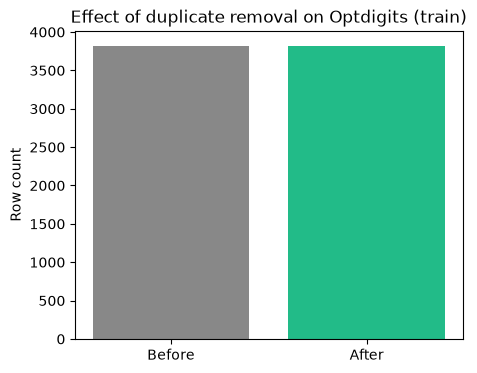

In [ ]:
# --- EDA visualization: rows before vs after duplicate removal ---
plt.figure(figsize=(5,4))
plt.bar(["Before", "After"], [n_before, n_after], color=["#888","#2b8"])
plt.ylabel("Row count")
plt.title("Effect of duplicate removal on Optdigits (train)")
plt.savefig("../../results/eda_visualizations/member1_duplicates_bar.png", dpi=150, bbox_inches="tight")
plt.show()

## Model Evaluation

A Decision Tree is a suitable interpretable multiclass baseline for the 64 pixel features. This experiment checks whether duplicate removal changes performance by tuning the same tree on the original and deduplicated training rows. `GridSearchCV` evaluates max depth, split size, and leaf size with 5-fold stratified CV; the held-out UCI test split is used only for final accuracy and macro F1. Macro F1 weights all ten digits equally.

In [3]:
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier

feature_cols = [f"pixel_{index}" for index in range(64)]
y_test = test["target"].astype(int)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

training_variants = {
    "Before duplicate removal": train,
    "After duplicate removal": train_clean,
}
results = []
for variant_name, variant_data in training_variants.items():
    search = GridSearchCV(
        DecisionTreeClassifier(random_state=42),
        {
            "max_depth": [None, 20, 35],
            "min_samples_split": [2, 5],
            "min_samples_leaf": [1, 2],
        },
        scoring={"accuracy": "accuracy", "macro_f1": "f1_macro"},
        refit="macro_f1",
        cv=cv,
        n_jobs=-1,
    )
    search.fit(variant_data[feature_cols], variant_data["target"].astype(int))
    predictions = search.predict(test[feature_cols])
    results.append({
        "Training data": variant_name,
        "CV accuracy": search.cv_results_["mean_test_accuracy"][search.best_index_],
        "CV macro F1": search.best_score_,
        "Test accuracy": accuracy_score(y_test, predictions),
        "Test macro F1": f1_score(y_test, predictions, average="macro"),
        "Best parameters": search.best_params_,
    })

cleaning_model_comparison = pd.DataFrame(results).sort_values(
    "CV macro F1", ascending=False
).reset_index(drop=True)
display(cleaning_model_comparison)

,Training data,CV accuracy,CV macro F1,Test accuracy,Test macro F1,Best parameters
0,Before duplicate removal,0.897983,0.898244,0.856427,0.856188,"{'max_depth': None, 'min_samples_leaf': 1, 'mi..."
1,After duplicate removal,0.897983,0.898244,0.856427,0.856188,"{'max_depth': None, 'min_samples_leaf': 1, 'mi..."


### Results and viva conclusion

The dataset contained zero duplicate training rows, so the before/after variants are identical. The tuned Decision Tree achieved 89.82% CV macro F1 and 85.64% test accuracy in both cases. This demonstrates that duplicate removal preserves model results when there are no duplicates to remove; it cannot improve the score here. The tree is easy to explain but performed below the SVC and Random Forest results elsewhere in the project, suggesting its decision boundaries may be too simple or unstable for some digit shapes. Future work could compare ensemble trees or tune pruning more broadly. The single official test split and small parameter grid limit the strength of generalization claims.